# Survey Analysis: AI-Augmented Agile Project Management

**Master's thesis portfolio project | Survey of real agile practitioners | Human–AI collaboration, trust and governance**

This notebook analyses a small practitioner survey about AI use in Agile project management. It combines descriptive statistics, exploratory reliability checks, non-parametric hypothesis tests, effect sizes and visualisations.

## Research questions

- How do practitioners perceive AI's contribution to efficiency and decision-making?
- How important are human judgement and oversight?
- How do explainability, data privacy and governance relate to trust and adoption?

## Dataset and interpretation

The source survey contains **20 respondents**. Findings are exploratory and should not be generalised to all Agile practitioners. Several multi-item constructs show limited or poor internal consistency, so construct-level results require caution and item-level findings are reported where appropriate.

## Reproducibility and privacy

There is no shareable copy of the cleaned survey export. This data analysis is for demonstration purposes. It was an anonymous survey from agile practioners.

## Data setup



In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 140)
ALPHA = 0.05

_candidates = [
    Path("data/survey_clean.csv"),
    Path("../data/survey_clean.csv"),
    Path("survey_clean.csv"),
]
INFILE = next((path for path in _candidates if path.exists()), None)
if INFILE is None:
    searched = ", ".join(str(path) for path in _candidates)
    raise FileNotFoundError(
        "Cleaned survey CSV not found. Place an anonymised file at "
        "data/survey_clean.csv (repository root) or next to this notebook. "
        f"Searched: {searched}"
    )

df = pd.read_csv(INFILE, sep=None, engine="python")
if df.shape[1] == 1:
    for sep in ["\t", ",", ";"]:
        candidate = pd.read_csv(INFILE, sep=sep)
        if candidate.shape[1] > 1:
            df = candidate
            print(f"Detected delimiter {sep!r}.")
            break
    else:
        raise ValueError(
            f"Could not parse {INFILE}: only one column detected. "
            f"First header: {df.columns[0][:200]!r}"
        )
print(f"Loaded survey data: {df.shape[0]} rows × {df.shape[1]} columns from {INFILE}")

LIKERT_ITEMS = {
    "AI_ImprovesDecisions":           "AI improves decision-making",
    "AI_ReducesTasks":                "AI reduces repetitive tasks",
    "Trust_AIRecommendations":        "I trust AI recommendations",
    "HumanJudgement_MoreImportant":   "Human judgement > AI in complex situations",
    "HumanOversight_Important":       "Human oversight remains important",
    "AI_BestWithHumanOversight":      "AI works best with human oversight",
    "Trust_NeedsExplainability":      "Trust requires explainability",
    "BlackBox_CanStillBeUseful":      "Black-box AI can still be useful",
    "NoGovernance_MoreRisk":          "Lack of governance increases risk",
    "PrivacyConcerns_InfluenceUse":   "Privacy concerns influence my use",
    "Governance_IncreasesConfidence": "Governance increases confidence",
    "Governance_ShouldBeAdapted":     "Governance should be adapted to teams",
}
items = list(LIKERT_ITEMS)
missing = [c for c in items if c not in df.columns]
if missing:
    raise KeyError(
        f"{len(missing)} expected Likert columns not found: {missing[:3]}... "
        f"Columns actually present: {list(df.columns)[:8]}... "
        f"-> Check the file version/delimiter or column renaming upstream.")
df[items] = df[items].apply(pd.to_numeric, errors="coerce")

# --- Data cleaning: remove completely empty survey rows ------------------------
# The raw Google Forms export contains blank rows (all Likert items missing).
# These carry no information and would distort N; they are removed and the
# removal is documented here for the methods section. Genuinely partial
# responses (e.g., one skipped item) are KEPT and handled pairwise per test.
empty_rows = df[items].isna().all(axis=1)
if empty_rows.any():
    print(f"Removed {empty_rows.sum()} completely empty row(s) "
          f"(all {len(items)} Likert items missing).")
    df = df[~empty_rows].reset_index(drop=True)
N = len(df)

# Traceability: this line documents the data basis for chapter 4.2.4
print(f"Data basis: {N} respondents x {df.shape[1]} variables")
print("Missing per Likert item (pairwise handling, NOT listwise):")
print(df[items].isna().sum()[lambda s: s > 0].to_string() or "  none")

Removed 2 completely empty row(s) (all 12 Likert items missing).
Data basis: 20 respondents x 38 variables
Missing per Likert item (pairwise handling, NOT listwise):
PrivacyConcerns_InfluenceUse    1


## 1. Sample Characteristics (4.2.4.1)

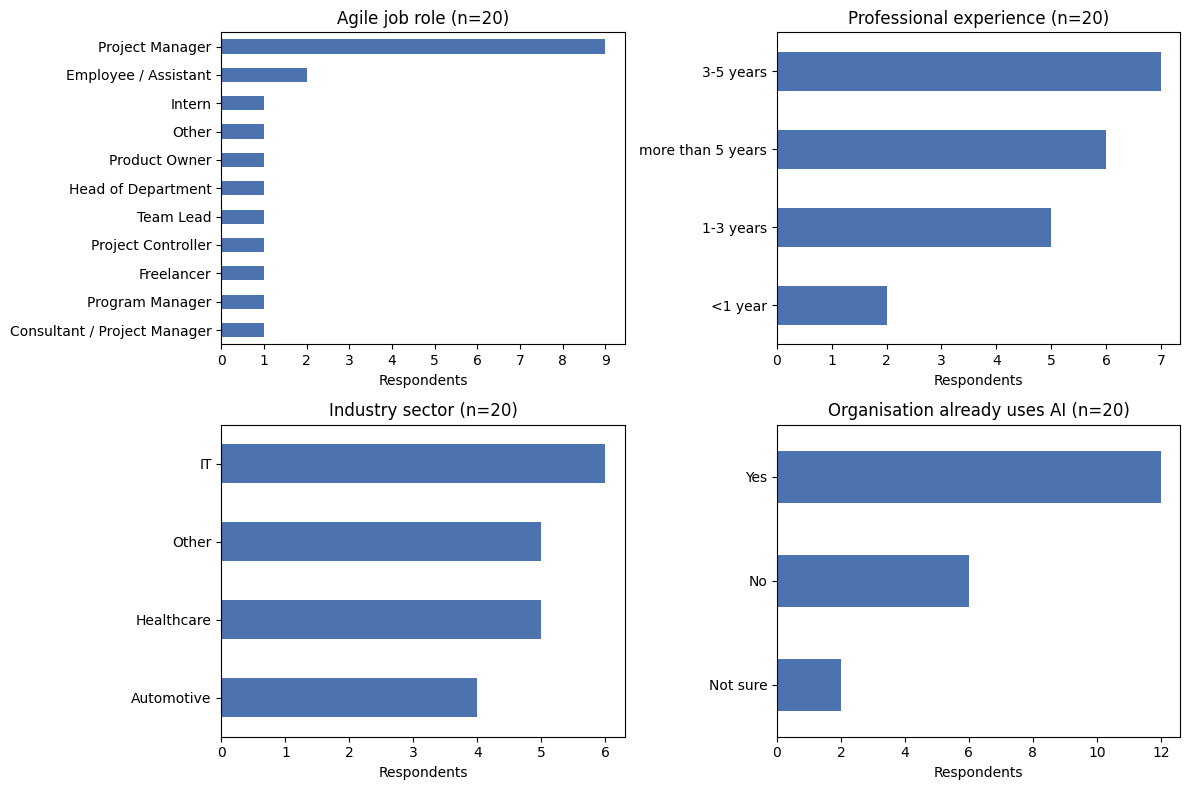


role_group:
role_group
Project Manager                 9
Employee / Assistant            2
Program Manager                 1
Consultant / Project Manager    1
Project Controller              1
Freelancer                      1
Team Lead                       1
Head of Department              1
Other                           1
Product Owner                   1
Intern                          1

experience_years:
experience_years
3-5 years            7
more than 5 years    6
1-3 years            5
<1 year              2

industry:
industry
IT            6
Healthcare    5
Other         5
Automotive    4

gender:
gender
Female    11
Male       9

org_uses_ai:
org_uses_ai
Yes         12
No           6
Not sure     2


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
order_exp = ["<1 year", "1-3 years", "3-5 years", "more than 5 years"]
for (col, title), ax in zip([("role_group", "Agile job role"),
                             ("experience_years", "Professional experience"),
                             ("industry", "Industry sector"),
                             ("org_uses_ai", "Organisation already uses AI")],
                            axes.ravel()):
    vc = df[col].value_counts()
    if col == "experience_years":
        vc = vc.reindex(order_exp)
    vc.sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(f"{title} (n={N})"); ax.set_xlabel("Respondents"); ax.set_ylabel("")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout(); fig.savefig("fig_1_sample_characteristics.png", dpi=300, bbox_inches="tight"); plt.show()

for col in ["role_group", "experience_years", "industry", "gender", "org_uses_ai"]:
    print(f"\n{col}:"); print(df[col].value_counts().to_string())

**Sample profile:** The dataset contains 20 respondents, with a substantial share reporting several years of Agile experience. Because the sample is small and non-probabilistic, these characteristics describe this sample only and do not establish representativeness.

## 2. AI Tools & Agile Tasks

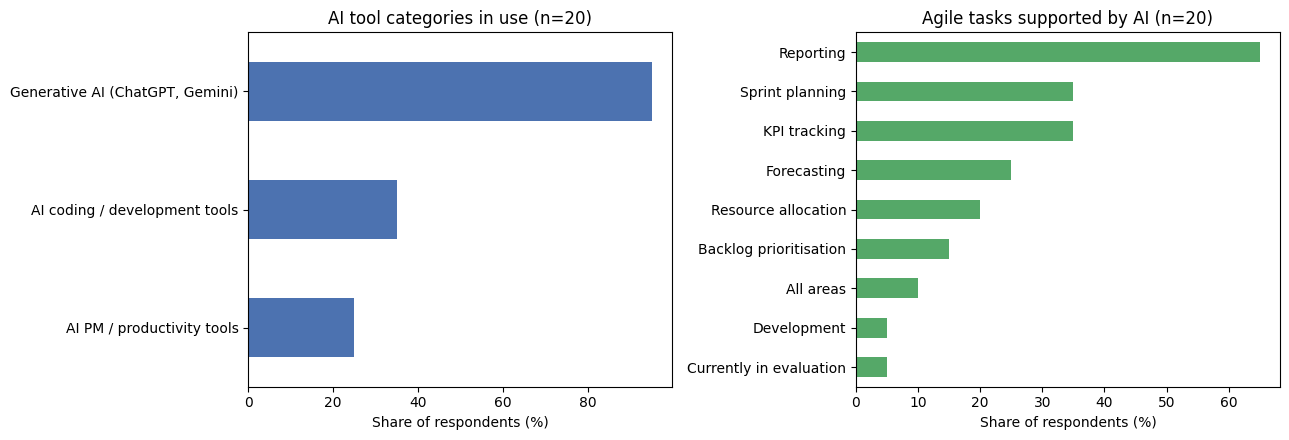

In [ ]:
tool_labels = {"tool_generative_ai_tools_eg_chatgpt_gemini": "Generative AI (ChatGPT, Gemini)",
               "tool_ai_coding_development_tools": "AI coding / development tools",
               "tool_ai_project_management_productivity_tools": "AI PM / productivity tools"}
task_labels = {"task_reporting": "Reporting", "task_sprint_planning": "Sprint planning",
               "task_kpi_tracking": "KPI tracking", "task_forecasting": "Forecasting",
               "task_resource_allocation": "Resource allocation",
               "task_backlog_prioritisation": "Backlog prioritisation", "task_for_all": "All areas",
               "task_currently_in_evaluation": "Currently in evaluation", "task_developing": "Development"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df[list(tool_labels)].mean().mul(100).rename(tool_labels).sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title(f"AI tool categories in use (n={N})"); axes[0].set_xlabel("Share of respondents (%)")
df[list(task_labels)].mean().mul(100).rename(task_labels).sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title(f"Agile tasks supported by AI (n={N})"); axes[1].set_xlabel("Share of respondents (%)")
for ax in axes: ax.set_ylabel("")
fig.tight_layout(); fig.savefig("fig_2_tools_tasks.png", dpi=300, bbox_inches="tight"); plt.show()

**AI tools and tasks:** Generative AI assistants were the most frequently reported tool category in this sample. Respondents reported more use for information-oriented activities such as reporting than for dedicated AI project-management tools. These percentages are descriptive and should not be generalised beyond the respondents.

## 3. Descriptive Statistics of Likert Items

,count,mean,std,median,IQR
AI improves decision-making,20.0,3.30,0.73,3.0,1.00
AI reduces repetitive tasks,20.0,4.20,0.77,4.0,1.00
I trust AI recommendations,20.0,2.70,0.80,3.0,1.00
Human judgement > AI in complex situations,20.0,4.00,0.86,4.0,2.00
Human oversight remains important,20.0,4.30,0.86,5.0,1.25
AI works best with human oversight,20.0,4.55,0.69,5.0,1.00
Trust requires explainability,20.0,3.80,0.89,4.0,1.00
Black-box AI can still be useful,20.0,3.30,0.98,3.0,1.00
Lack of governance increases risk,20.0,3.65,0.81,4.0,1.00
Privacy concerns influence my use,19.0,3.53,1.12,4.0,1.00


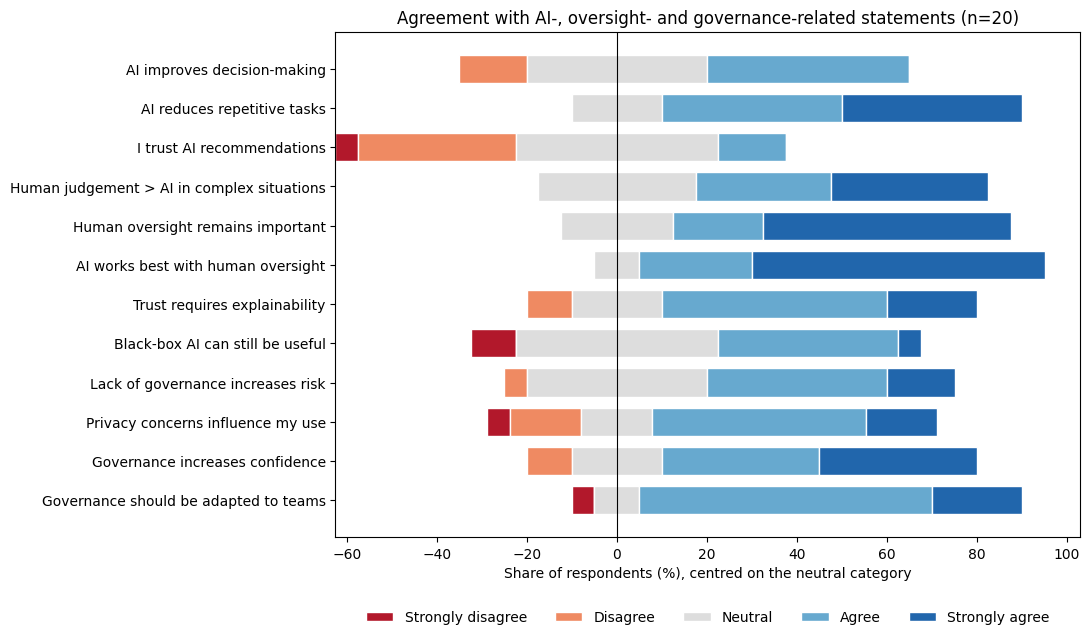

In [ ]:
desc = df[items].agg(["count", "mean", "std", "median"]).T
desc["IQR"] = df[items].quantile(0.75) - df[items].quantile(0.25)
desc.index = [LIKERT_ITEMS[i] for i in desc.index]
desc.round(2).to_csv("table_1_descriptives.csv")
display(desc.round(2))

colors = ["#B2182B", "#EF8A62", "#DDDDDD", "#67A9CF", "#2166AC"]
lik_labels = ["Strongly disagree", "Disagree", "Neutral", "Agree", "Strongly agree"]
dist = pd.DataFrame({i: df[i].value_counts(normalize=True).reindex([1,2,3,4,5], fill_value=0)
                     for i in items}).T * 100
dist.index = [LIKERT_ITEMS[i] for i in dist.index]
fig, ax = plt.subplots(figsize=(11, 6.5))
left = -(dist[1] + dist[2] + dist[3] / 2)
for val, col, lab in zip([1,2,3,4,5], colors, lik_labels):
    ax.barh(dist.index, dist[val], left=left, color=col, label=lab, edgecolor="white", height=0.72)
    left = left + dist[val]
ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
ax.set_xlabel("Share of respondents (%), centred on the neutral category")
ax.set_title(f"Agreement with AI-, oversight- and governance-related statements (n={N})")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.tight_layout(); fig.savefig("fig_3_likert_diverging.png", dpi=300, bbox_inches="tight"); plt.show()

**Descriptive results:** Respondents rated reducing repetitive tasks more positively than improving decision-making, while trust in AI recommendations was comparatively lower. Human oversight and combining AI with human judgement received high agreement. This pattern is consistent with AI being viewed as decision support rather than an autonomous decision-maker in this sample.

### Detailed Interpretation of Likert Items

Looking closer at the descriptive distribution of agreement, several key dynamics emerge within this practitioner sample:

1. **Highest Agreement (AI Works Best with Human Oversight):** The statement *"AI works best with human oversight"* (alongside general human oversight importance) received the strongest agreement. This underscores a clear practitioner mindset: AI is not seen as an human replacement, it´s perceived as a collaborative tool that requires a 'human-in-the-loop' to be truly effective in Agile environments.

2. **Lowest Agreement (Trust in AI Recommendations):** on the other hand, the statement *"I trust AI recommendations"* received the lowest overall agreement (with a median of 3.0 and a negative rank-biserial effect size of -0.50). Practitioners are highly cautious about blindly following a ML output. It´s an indicator of a trust gap that must be bridged before prescriptive AI is widely adopted in an agile organisation.
* **The Role of Privacy Concerns:** Interestingly, *"Privacy concerns influence my use"* received moderate agreement with almost no outright disagreement. Even though trust in AI recommendations is low, privacy concerns do not act as an absolute blocker to using these tools; rather, they represent a critical context or constraint that agile practitioners actively navigate when deploying AI in their daily workflows.


## 4. Reliability Analysis (Cronbach's alpha) & Normality Check — Table 3
Constructs follow the operationalisation of the thesis hypothesis constructs. Decision rule: alpha >= .60 (exploratory threshold) → construct used as *secondary* evidence; below → item-level testing. The Shapiro–Wilk test documents why non-parametric tests are used.

In [ ]:
def cronbach_alpha(frame):
    frame = frame.dropna(); k = frame.shape[1]
    return k/(k-1) * (1 - frame.var(ddof=1).sum() / frame.sum(axis=1).var(ddof=1)), len(frame)

# Note: no missing values across the four constructs

def spearman_brown(frame):
    r = frame.dropna().corr(method="pearson").iloc[0, 1]
    return 2*r / (1+r)

df["BlackBox_rev"] = 6 - df["BlackBox_CanStillBeUseful"]
CONSTRUCTS = {
    "EFF Perceived Effectiveness": ["AI_ImprovesDecisions", "AI_ReducesTasks"],
    "OVR Oversight/Human Primacy": ["HumanOversight_Important", "AI_BestWithHumanOversight",
                                     "HumanJudgement_MoreImportant"],
    "EXP Explainability Requirement": ["Trust_NeedsExplainability", "BlackBox_rev"],
    "GOV Governance Need": ["NoGovernance_MoreRisk", "Governance_IncreasesConfidence",
                             "Governance_ShouldBeAdapted"],
}
rows = []
for name, cols in CONSTRUCTS.items():
    a, n = cronbach_alpha(df[cols])
    sb = spearman_brown(df[cols]) if len(cols) == 2 else np.nan
    rows.append([name, len(cols), round(a, 3), round(sb, 3) if not np.isnan(sb) else "-", n])
rel = pd.DataFrame(rows, columns=["Construct", "k", "Cronbach alpha", "Spearman-Brown", "n"])
rel.to_csv("table_3_reliability.csv", index=False); display(rel)

# Construct scores ONLY where alpha >= .60
df["EFF"] = df[CONSTRUCTS["EFF Perceived Effectiveness"]].mean(axis=1)
df["OVR"] = df[CONSTRUCTS["OVR Oversight/Human Primacy"]].mean(axis=1)
print("EFF & OVR used as secondary construct scores; EXP (alpha<0) and GOV (alpha<.60) -> item level.")

print("\nShapiro-Wilk on construct scores (justifies non-parametric tests):")
# p < 0.05 -> variable is not normally distributed
# p ≥ 0.05 -> variable is normally distributed
for c in ["EFF", "OVR"]:
    w, p = stats.shapiro(df[c].dropna())
    print(f"  {c}: W={w:.3f}, p={p:.4f} -> {'not ' if p < .05 else ''}normally distributed")

,Construct,k,Cronbach alpha,Spearman-Brown,n
0,EFF Perceived Effectiveness,2,0.619,0.62,20
1,OVR Oversight/Human Primacy,3,0.609,-,20
2,EXP Explainability Requirement,2,-0.904,-0.91,20
3,GOV Governance Need,3,0.489,-,20


EFF & OVR used as secondary construct scores; EXP (alpha<0) and GOV (alpha<.60) -> item level.

Shapiro-Wilk on construct scores (justifies non-parametric tests):
  EFF: W=0.854, p=0.0062 -> not normally distributed
  OVR: W=0.906, p=0.0535 -> normally distributed


**Reliability and normality:**

Reliability estimates vary substantially across constructs. The explainability construct has a negative Cronbach's alpha in this sample, and the governance construct is below the exploratory threshold used here. These results indicate that the corresponding items should not be treated as a reliable unified scale; item-level analyses are more defensible. With a sample of 20, reliability estimates are also highly uncertain.

1. **Explainability as a Threshold:** Explainability acts as a critical threshold criterion for building confidence. However, a lack of explainability does not serve as an absolute blocker to using AI tools when immediate utility or efficiency gains are present.
2. **Team-Level Governance Needs:** To build a robust foundation of trust, governance framework designs must not be top-down or rigid. Instead, they need to be adapted to each team's specific context and needs, thereby establishing a practical and accepted threshold of trust across the organization.


## 5. Hypothesis Testing — item-level Wilcoxon, effect sizes, Holm
Primary tests per thesis hypothesis; rank-biserial r as effect size; Holm–Bonferroni over the confirmatory family (m = 10).

In [ ]:
# Note:The Wilcoxon test checks whether the responses lie systematically above
# or below the neutral point (3): W-statistic → sum of rank differences,
# p-value → probability that the result is due to chance
# p < 0.05 → significant deviation from the neutral point,
# p ≥ 0.05 → no significant deviation
# rank-biseral: r_rb is the effect size is reported to measure the strength
# of the tendency (regardless of whether it is statistically significant).
# The Wilcoxon effect size r_rb ranges from –1 to +1:
# +1 → maximum agreement; 0 → no direction; –1 → maximum disagreement
#Interpretation of strength: 0.20 → small effect; 0.50 → medium; 0.80+ → large

def wilcoxon_neutral(x):
    x = pd.to_numeric(x, errors="coerce").dropna()
    d = (x - 3)[lambda s: s != 0]
    ranks = stats.rankdata(np.abs(d))
    r_rb = (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()
    w, p = stats.wilcoxon(x - 3, alternative="greater")
    return {"Mdn": x.median(), "W": w, "p": p, "r_rb": r_rb, "n": len(x)}

wilc = {c: wilcoxon_neutral(df[c]) for c in items}

CONFIRMATORY = ["AI_ImprovesDecisions", "AI_ReducesTasks", "HumanOversight_Important",
                "AI_BestWithHumanOversight", "HumanJudgement_MoreImportant",
                "Trust_NeedsExplainability", "PrivacyConcerns_InfluenceUse",
                "NoGovernance_MoreRisk", "Governance_IncreasesConfidence",
                "Governance_ShouldBeAdapted"]
pv = np.array([wilc[c]["p"] for c in CONFIRMATORY])
holm = np.empty_like(pv); prev = 0.0
for rank, idx in enumerate(np.argsort(pv)):
    prev = max(prev, min(1.0, (len(pv) - rank) * pv[idx])); holm[idx] = prev

# Note: Holm-Bonferroni = protection against "false positives":
# Prevents chance significance (p-value) across 10 hypotheses,
# sorts all p-values, and yields the most robust findings.

t2 = pd.DataFrame([{"Item": c, "Mdn": wilc[c]["Mdn"], "W": wilc[c]["W"],
                    "p": round(wilc[c]["p"], 4), "p_Holm": round(h, 4),
                    "r_rb": round(wilc[c]["r_rb"], 2), "n": wilc[c]["n"]}
                   for c, h in zip(CONFIRMATORY, holm)])
t2.to_csv("table_2_wilcoxon_holm.csv", index=False); display(t2)

# Non-directional context items (reported without Holm: not confirmatory)
for c in ["Trust_AIRecommendations", "BlackBox_CanStillBeUseful"]:
    r = wilc[c]
    print(f"{c} (context): Mdn={r['Mdn']}, W={r['W']}, p={r['p']:.4f}, r_rb={r['r_rb']:.2f}")

,Item,Mdn,W,p,p_Holm,r_rb,n
0,AI_ImprovesDecisions,3.0,58.5,0.0416,0.0640,0.50,20
1,AI_ReducesTasks,4.0,136.0,0.0001,0.0013,1.00,20
2,HumanOversight_Important,5.0,120.0,0.0002,0.0014,1.00,20
3,AI_BestWithHumanOversight,5.0,171.0,0.0000,0.0005,1.00,20
4,HumanJudgement_MoreImportant,4.0,91.0,0.0005,0.0037,1.00,20
5,Trust_NeedsExplainability,4.0,123.0,0.0014,0.0055,0.81,20
6,PrivacyConcerns_InfluenceUse,4.0,102.0,0.0320,0.0640,0.50,19
7,NoGovernance_MoreRisk,4.0,73.0,0.0025,0.0076,0.87,20
8,Governance_IncreasesConfidence,4.0,126.0,0.0010,0.0050,0.85,20
9,Governance_ShouldBeAdapted,4.0,155.0,0.0007,0.0045,0.81,20


Trust_AIRecommendations (context): Mdn=3.0, W=16.5, p=0.9456, r_rb=-0.50
BlackBox_CanStillBeUseful (context): Mdn=3.0, W=46.0, p=0.1132, r_rb=0.39


**Item-level tests:** The strongest descriptive and inferential signals concern human oversight and governance. P-values are adjusted using the Holm–Bonferroni procedure for the defined family of tests. Given the small sample and exploratory design, statistical significance should be interpreted cautiously and alongside effect sizes and item distributions.

### Methodological Note on Construct Formation & Item-Level Transition
* **Why constructs were formed:** Multi-item constructs (EFF, OVR, EXP, GOV) were originally established to represent the core theoretical hypotheses of the thesis. Grouping multiple questions into unified scales is a standard procedure intended to reduce measurement error and capture broader latent attitudes.
 **Why we shifted to item-level tests:** Our exploratory reliability analysis (Section 4) revealed that while EFF and OVR met the exploratory threshold, the constructs for **Explainability (EXP)** and **Governance (GOV)** did not show sufficient internal consistency (Cronbach's alpha was negative for EXP and below 0.60 for GOV). Treating these unstable scales as single unified variables would lead to distorted, unreliable findings. Consequently, shifting to non-parametric item-level Wilcoxon signed-rank tests ensures statistical validity, allowing us to test specific, actionable attitudes at the individual question level.


In [ ]:
# H6: PAIRED Wilcoxon (robust: coerce numeric, drop incomplete pairs)
# Note: It shows how far above the neutral point the level of agreement
# lies—regardless of the p-value. Interpretation:
# r_rb = 1.00 → maximum agreement, r_rb = 0.50 → moderate, r_rb = 0.20 → small
# r_rb = 0 → no direction

pair6 = df[["HumanJudgement_MoreImportant", "Trust_AIRecommendations"]].apply(
    pd.to_numeric, errors="coerce").dropna()
d6 = pair6.iloc[:, 0] - pair6.iloc[:, 1]
dd6 = d6[d6 != 0]; ranks6 = stats.rankdata(np.abs(dd6))
r_rb6 = (ranks6[dd6 > 0].sum() - ranks6[dd6 < 0].sum()) / ranks6.sum()
w6, p6 = stats.wilcoxon(pair6.iloc[:, 0], pair6.iloc[:, 1], alternative="greater")
print(f"H6 paired Wilcoxon: Mdn {pair6.iloc[:,0].median():.0f} vs {pair6.iloc[:,1].median():.0f}, "
      f"W={w6}, p={p6:.4f}, r_rb={r_rb6:.2f}, n={len(pair6)}")

#  Hypothesis-guided Spearman correlations (secondary evidence) — Table 4
def spearman(a, b):
    m = df[[a, b]].apply(pd.to_numeric, errors="coerce").dropna()
    rho, p = stats.spearmanr(m[a], m[b]); return rho, p, len(m)

SP = [("H1c", "ai_usage_frequency", "EFF", "Adoption ~ perceived effectiveness"),
      ("H2c", "EFF", "OVR", "Effectiveness ~ oversight (tests 'even when' clause)"),
      ("H3c", "Trust_NeedsExplainability", "Trust_AIRecommendations",
       "Explainability requirement ~ current trust (caveat: conditional item)"),
      ("H4b", "PrivacyConcerns_InfluenceUse", "ai_usage_frequency", "Privacy concerns ~ adoption"),
      ("H5d", "Governance_IncreasesConfidence", "Trust_AIRecommendations",
       "Governance confidence ~ trust (exploratory)")]
t4 = pd.DataFrame([{"Tag": t, "Test": d, "rho": round(spearman(a, b)[0], 3),
                    "p": round(spearman(a, b)[1], 4), "n": spearman(a, b)[2]}
                   for t, a, b, d in SP])
t4.to_csv("table_4_spearman.csv", index=False); display(t4)

# --- Exploratory: Mann-Whitney by organisational AI use (robust labels) ---
grp = df["org_uses_ai"].astype(str).str.strip().str.lower()
mask = grp == "yes"
print(f"\nMann-Whitney org uses AI: labels={grp.value_counts().to_dict()}")
for c in ["ai_usage_frequency", "EFF", "Trust_AIRecommendations", "OVR"]:
    x = pd.to_numeric(df.loc[mask, c], errors="coerce").dropna()
    y = pd.to_numeric(df.loc[~mask, c], errors="coerce").dropna()
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    print(f"  {c}: U={u}, p={p:.4f}, Mdn {x.median():.2f} vs {y.median():.2f} (n={len(x)}/{len(y)})")

H6 paired Wilcoxon: Mdn 4 vs 3, W=159.0, p=0.0005, r_rb=0.86, n=20


,Tag,Test,rho,p,n
0,H1c,Adoption ~ perceived effectiveness,0.326,0.1603,20
1,H2c,Effectiveness ~ oversight (tests 'even when' c...,0.261,0.2666,20
2,H3c,Explainability requirement ~ current trust (ca...,-0.080,0.7368,20
3,H4b,Privacy concerns ~ adoption,-0.135,0.5804,19
4,H5d,Governance confidence ~ trust (exploratory),0.452,0.0457,20



Mann-Whitney org uses AI: labels={'yes': 12, 'no': 6, 'not sure': 2}
  ai_usage_frequency: U=73.5, p=0.0342, Mdn 4.00 vs 2.50 (n=12/8)
  EFF: U=70.5, p=0.0732, Mdn 4.00 vs 3.75 (n=12/8)
  Trust_AIRecommendations: U=66.0, p=0.1465, Mdn 3.00 vs 2.00 (n=12/8)
  OVR: U=63.5, p=0.2381, Mdn 4.67 vs 4.17 (n=12/8)


**H6 and exploratory associations:** Paired comparisons and correlations provide additional context on the relationship between trust, human judgement and oversight. These analyses are exploratory, especially with N = 20, and should be treated as hypothesis-generating rather than conclusive evidence.

# 6. Trust vs. Oversight Visualisation & Exploratory Group Descriptives (Appendix)

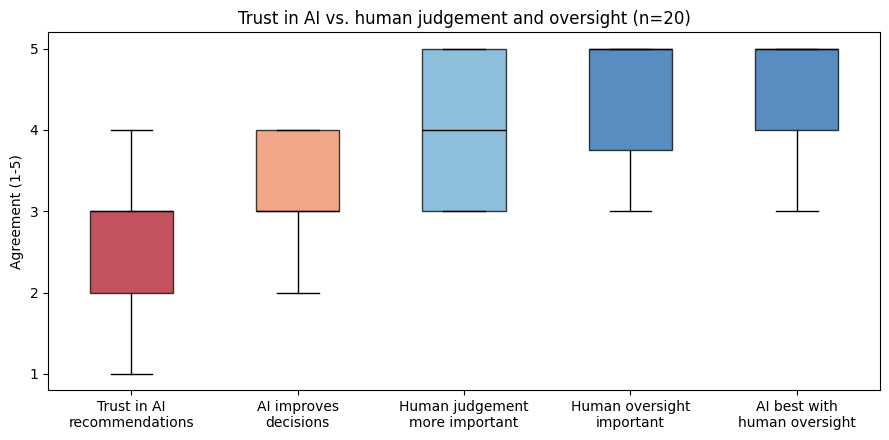

Median EFF / OVR by experience:
                    EFF   OVR
experience_years             
<1 year            3.00  4.50
1-3 years          4.00  3.67
3-5 years          4.00  4.33
more than 5 years  4.25  4.83

Median EFF / OVR by AI familiarity band:
                     EFF   OVR
ai_familiarity_band           
Low (1-2)            3.5  4.17
Moderate (3)         4.0  4.50
High (4-5)           4.0  4.50


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
comp = df[["Trust_AIRecommendations", "AI_ImprovesDecisions", "HumanJudgement_MoreImportant",
           "HumanOversight_Important", "AI_BestWithHumanOversight"]]
labels = ["Trust in AI\nrecommendations", "AI improves\ndecisions", "Human judgement\nmore important",
          "Human oversight\nimportant", "AI best with\nhuman oversight"]
bp = ax.boxplot([comp[c].dropna() for c in comp.columns], tick_labels=labels,
                patch_artist=True, medianprops=dict(color="black"))
for patch, col in zip(bp["boxes"], ["#B2182B", "#EF8A62", "#67A9CF", "#2166AC", "#2166AC"]):
    patch.set_facecolor(col); patch.set_alpha(0.75)
ax.set_ylabel("Agreement (1-5)"); ax.set_yticks([1, 2, 3, 4, 5])
ax.set_title(f"Trust in AI vs. human judgement and oversight (n={N})")
fig.tight_layout(); fig.savefig("fig_4_trust_vs_oversight.png", dpi=300, bbox_inches="tight"); plt.show()

# Exploratory descriptives by experience and AI familiarity (appendix; ordinal-safe: medians)
def band(x):
    if pd.isna(x): return np.nan
    return "Low (1-2)" if x <= 2 else ("Moderate (3)" if x == 3 else "High (4-5)")
df["ai_familiarity_band"] = df["ai_familiarity"].apply(band)
print("Median EFF / OVR by experience:")
print(df.groupby("experience_years")[["EFF", "OVR"]].median()
        .reindex(["<1 year", "1-3 years", "3-5 years", "more than 5 years"]).round(2).to_string())
print("\nMedian EFF / OVR by AI familiarity band:")
print(df.groupby("ai_familiarity_band")[["EFF", "OVR"]].median()
        .reindex(["Low (1-2)", "Moderate (3)", "High (4-5)"]).round(2).to_string())

**Trust versus oversight:** In this sample, agreement with human oversight and human judgement was higher than trust in AI recommendations. Group-level differences by experience or AI familiarity are descriptive only; the small subgroups do not support strong conclusions about population differences.

## 7. Hypothesis–Construct–Test Mapping (Table 5)
Every statistic in this table is taken from the objects computed above. Q# refer to the operationalisation table in 4.2.1.

In [ ]:
s_h1 = spearman("ai_usage_frequency", "EFF"); s_h2 = spearman("EFF", "OVR")
s_h3 = spearman("Trust_NeedsExplainability", "Trust_AIRecommendations")
s_h4 = spearman("PrivacyConcerns_InfluenceUse", "ai_usage_frequency")
s_h5 = spearman("Governance_IncreasesConfidence", "Trust_AIRecommendations")
W = lambda c: wilc[c]; H = dict(zip(CONFIRMATORY, holm))
share = lambda c: f"{df[c].mean()*100:.0f} %"

rows = [
 {"Hypothesis": "H1: AI tools improve decision-making and efficiency",
  "Survey questions (Q#)": "Q11a decisions; Q11e task relief; Q7 usage",
  "Construct (reliability)": "Perceived Effectiveness (alpha = .62)",
  "Test": "One-sample Wilcoxon per item (primary); Spearman usage~EFF (secondary)",
  "Result": (f"Tasks: Mdn={W('AI_ReducesTasks')['Mdn']:.0f}, p_Holm={H['AI_ReducesTasks']:.3f}, "
             f"r_rb={W('AI_ReducesTasks')['r_rb']:.2f} | Decisions: Mdn={W('AI_ImprovesDecisions')['Mdn']:.0f}, "
             f"p_Holm={H['AI_ImprovesDecisions']:.3f} | rho={s_h1[0]:.2f}, p={s_h1[1]:.3f}"),
  "Decision": "Partially supported",
  "Interpretation in agile PM": (f"AI relieves the information-heavy ceremonies where teams already use it "
      f"(reporting {share('task_reporting')}, KPI tracking {share('task_kpi_tracking')}, sprint planning "
      f"{share('task_sprint_planning')}), freeing time for judgement-intensive work; AI output enters "
      f"sprint decisions as prepared evidence, not as the decision.")},
 {"Hypothesis": "H2: Human oversight remains important even when AI improves performance",
  "Survey questions (Q#)": "Q11b oversight; Q11f best-with-oversight; Q11d judgement",
  "Construct (reliability)": "Oversight/Human Primacy (alpha = .61)",
  "Test": "One-sample Wilcoxon per item (primary); Spearman EFF~OVR (secondary)",
  "Result": (f"Oversight: Mdn={W('HumanOversight_Important')['Mdn']:.0f}, "
             f"p_Holm={H['HumanOversight_Important']:.3f}, r_rb={W('HumanOversight_Important')['r_rb']:.2f}; "
             f"EFF~OVR rho=+{s_h2[0]:.2f} (not negative)"),
  "Decision": "Supported",
  "Interpretation in agile PM": ("Oversight is a constant, not a transition phase: AI-generated forecasts, "
      "risk flags and backlog suggestions need a defined human checkpoint (PO sign-off in refinement, "
      "review of AI-drafted reports) - a 'definition of done' for AI-assisted artefacts.")},
 {"Hypothesis": "H3: Trust depends on understanding how AI reached its conclusions",
  "Survey questions (Q#)": "Q12a explainability; contrast Q12b black-box; Q11c trust",
  "Construct (reliability)": "Item level (EXP pair not unidimensional, alpha < 0)",
  "Test": "One-sample Wilcoxon on Q12a (primary); Spearman Q12a~Q11c (secondary, caveat)",
  "Result": (f"Mdn={W('Trust_NeedsExplainability')['Mdn']:.0f}, p_Holm={H['Trust_NeedsExplainability']:.3f}, "
             f"r_rb={W('Trust_NeedsExplainability')['r_rb']:.2f}; rho={s_h3[0]:.2f} (null, conditional item)"),
  "Decision": "Supported as stated acceptance condition",
  "Interpretation in agile PM": ("Explainability is a threshold condition for acting on AI output: a "
      "sprint-risk warning is only actionable if the team sees WHY (e.g., feature attributions in the "
      "Dataset-1 Jira model). Black-box scores are disqualified for decision-critical uses.")},
 {"Hypothesis": "H4: Privacy/governance concerns influence adoption",
  "Survey questions (Q#)": "Q12d privacy; Q7 usage",
  "Construct (reliability)": "Item level",
  "Test": "One-sample Wilcoxon (primary); Spearman concerns~usage (secondary)",
  "Result": (f"Mdn={W('PrivacyConcerns_InfluenceUse')['Mdn']:.0f}, p={W('PrivacyConcerns_InfluenceUse')['p']:.3f} "
             f"(p_Holm={H['PrivacyConcerns_InfluenceUse']:.3f}), r_rb={W('PrivacyConcerns_InfluenceUse')['r_rb']:.2f}; "
             f"rho={s_h4[0]:.2f}, n.s."),
  "Decision": "Partially supported",
  "Interpretation in agile PM": ("Concerns shape WHAT teams feed into tools (sprint data, customer stories, "
      "velocity) rather than whether they use them - actionable as data-handling rules per tool class, "
      "not tool bans.")},
 {"Hypothesis": "H5: Organisations need clear AI governance frameworks",
  "Survey questions (Q#)": "Q12c risk; Q12e confidence; Q12f adapted",
  "Construct (reliability)": "Item level (alpha = .49, no reliable scale)",
  "Test": "One-sample Wilcoxon per item (primary); exploratory Spearman GovConfidence~Trust",
  "Result": (f"All Mdn=4; p_Holm: risk={H['NoGovernance_MoreRisk']:.3f}, "
             f"confidence={H['Governance_IncreasesConfidence']:.3f}, adapted={H['Governance_ShouldBeAdapted']:.3f}; "
             f"exploratory rho={s_h5[0]:.2f}, p={s_h5[1]:.3f}"),
  "Decision": "Supported",
  "Interpretation in agile PM": ("Governance is perceived as trust-enabling, not overhead - and must be "
      "adaptable per team (tightest consensus, IQR = 0): org-level guardrails tailored by each team like "
      "a working agreement, not one-size-fits-all policy.")},
 {"Hypothesis": "H6: Human judgement trusted more than AI recommendations in complex situations",
  "Survey questions (Q#)": "Q11d vs Q11c (within-subject)",
  "Construct (reliability)": "Two single items, paired",
  "Test": "Paired Wilcoxon signed-rank (robust: incomplete pairs dropped)",
  "Result": (f"Mdn {pair6.iloc[:,0].median():.0f} vs {pair6.iloc[:,1].median():.0f}, W={w6:.0f}, "
             f"p={p6:.4f}, r_rb={r_rb6:.2f}, n={len(pair6)}"),
  "Decision": "Supported",
  "Interpretation in agile PM": ("Within the same respondents, human judgement outranks AI advice for "
      "escalations, conflicting priorities and mid-sprint scope decisions: AI prepares, humans decide - "
      "the empirical core of the thesis argument.")},
]
mapping = pd.DataFrame(rows)
mapping.to_csv("table_5_hypothesis_mapping.csv", index=False)
with open("table_5_hypothesis_mapping.md", "w") as f: f.write(mapping.to_markdown(index=False))
display(mapping)

,Hypothesis,Survey questions (Q#),Construct (reliability),Test,Result,Decision,Interpretation in agile PM
0,H1: AI tools improve decision-making and effic...,Q11a decisions; Q11e task relief; Q7 usage,Perceived Effectiveness (alpha = .62),One-sample Wilcoxon per item (primary); Spearm...,"Tasks: Mdn=4, p_Holm=0.001, r_rb=1.00 | Decisi...",Partially supported,AI relieves the information-heavy ceremonies w...
1,H2: Human oversight remains important even whe...,Q11b oversight; Q11f best-with-oversight; Q11d...,Oversight/Human Primacy (alpha = .61),One-sample Wilcoxon per item (primary); Spearm...,"Oversight: Mdn=5, p_Holm=0.001, r_rb=1.00; EFF...",Supported,"Oversight is a constant, not a transition phas..."
2,H3: Trust depends on understanding how AI reac...,Q12a explainability; contrast Q12b black-box; ...,"Item level (EXP pair not unidimensional, alpha...",One-sample Wilcoxon on Q12a (primary); Spearma...,"Mdn=4, p_Holm=0.005, r_rb=0.81; rho=-0.08 (nul...",Supported as stated acceptance condition,Explainability is a threshold condition for ac...
3,H4: Privacy/governance concerns influence adop...,Q12d privacy; Q7 usage,Item level,One-sample Wilcoxon (primary); Spearman concer...,"Mdn=4, p=0.032 (p_Holm=0.064), r_rb=0.50; rho=...",Partially supported,Concerns shape WHAT teams feed into tools (spr...
4,H5: Organisations need clear AI governance fra...,Q12c risk; Q12e confidence; Q12f adapted,"Item level (alpha = .49, no reliable scale)",One-sample Wilcoxon per item (primary); explor...,"All Mdn=4; p_Holm: risk=0.008, confidence=0.00...",Supported,"Governance is perceived as trust-enabling, not..."
5,H6: Human judgement trusted more than AI recom...,Q11d vs Q11c (within-subject),"Two single items, paired",Paired Wilcoxon signed-rank (robust: incomplet...,"Mdn 4 vs 3, W=159, p=0.0005, r_rb=0.86, n=20",Supported,"Within the same respondents, human judgement o..."


**Hypothesis mapping:** The summary table links each hypothesis to its survey items, test, effect size and interpretation. The results suggest strong interest in efficiency benefits alongside continued demand for human oversight and governance. Because the sample is small and some constructs have weak reliability, conclusions should remain exploratory.

## 8. Synthesis and limitations

The survey responses suggest that practitioners value AI for reducing repetitive work while retaining human judgement, explainability and governance as important safeguards. These patterns help contextualise the predictive modelling work in this portfolio: forecasts should be presented as inputs to human decisions, not as autonomous decisions.

**Limitations**

- The sample is small and non-probabilistic (**N = 20**); findings are not representative estimates.
- Some multi-item constructs have low or negative reliability estimates, so construct-level interpretation is limited.
- Multiple statistical tests and subgroup analyses increase the risk of chance findings, even with correction where specified.
- Self-reported attitudes and usage do not establish actual organisational behaviour or causal relationships.
- The survey is intended to contextualise the thesis framework, not independently validate model performance.